In [1]:
import os
import sys
import pandas as pd

cwd = os.getcwd()
project_root = cwd

if os.path.basename(cwd) == "notebooks":
    project_root = os.path.abspath("..")
elif not os.path.exists(os.path.join(cwd, "src")):
    for candidate in [os.path.abspath(".."), os.path.abspath(".")]:
        if os.path.exists(os.path.join(candidate, "src")):
            project_root = candidate
            break

if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.preparacao_dados import preparar_dados
from src.modelos import criar_modelos
from src.avaliacao import (
    treinar_modelos,
    validar_modelos,
    avaliar_modelos,
)


In [2]:
X_train, X_test, y_train, y_test = preparar_dados(
    "../data/dataset.csv"
)

In [3]:
print("Total de pacientes:", len(y_train) + len(y_test))

print("\nDistribuição total:")
print(pd.concat([y_train, y_test]).value_counts())

print("\nDistribuição percentual:")
print(
    pd.concat([y_train, y_test])
    .value_counts(normalize=True)
    .mul(100)
)

Total de pacientes: 5855

Distribuição total:
sepsis
0    5224
1     631
Name: count, dtype: int64

Distribuição percentual:
sepsis
0    89.222886
1    10.777114
Name: proportion, dtype: float64


In [4]:
modelos = criar_modelos()

In [5]:
modelos_treinados = treinar_modelos(
    modelos,
    X_train,
    y_train
)

In [6]:
resultados_validacao = validar_modelos(
    modelos,
    X_train,
    y_train
)

In [7]:
resultados_teste = avaliar_modelos(
    modelos_treinados,
    X_test,
    y_test
)

c:\Users\Pichau\Documents\limezashi\TCC_SAIS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pichau\Documents\limezashi\TCC_SAIS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pichau\Documents\limezashi\TCC_SAIS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

In [8]:
for nome, resultado in resultados_validacao.items():

    print(f"\n{nome}")
    print("-" * 40)
    print(f"AUC médio: {resultado['media_auc']:.4f}")
    print(f"Desvio padrão: {resultado['desvio_auc']:.4f}")
    print(f"Scores: {resultado['scores_auc']}")


Regressão Logística
----------------------------------------
AUC médio: 0.6455
Desvio padrão: 0.0230
Scores: [0.64842011 0.63759534 0.68386707 0.6455185  0.61230806]

Random Forest
----------------------------------------
AUC médio: 0.6086
Desvio padrão: 0.0208
Scores: [0.57839073 0.63305936 0.62455588 0.61661495 0.59033616]

XGBoost
----------------------------------------
AUC médio: 0.5787
Desvio padrão: 0.0326
Scores: [0.56323132 0.58214506 0.63976266 0.56252073 0.54606035]

SVM
----------------------------------------
AUC médio: 0.5096
Desvio padrão: 0.0306
Scores: [0.45485338 0.49747738 0.53701028 0.52861339 0.53008834]


In [9]:
for nome, resultado in resultados_teste.items():

    print(f"\n{nome}")
    print("-" * 40)
    print(f"ROC-AUC: {resultado['auc']:.4f}")

    print("\nMatriz de Confusão:")
    print(resultado["matriz_confusao"])

    print("\nClassification Report:")
    print(resultado["relatorio"])


Regressão Logística
----------------------------------------
ROC-AUC: 0.6861

Matriz de Confusão:
[[1045    0]
 [ 125    1]]

Classification Report:
{'0': {'precision': 0.8931623931623932, 'recall': 1.0, 'f1-score': 0.9435665914221218, 'support': 1045.0}, '1': {'precision': 1.0, 'recall': 0.007936507936507936, 'f1-score': 0.015748031496062992, 'support': 126.0}, 'accuracy': 0.8932536293766012, 'macro avg': {'precision': 0.9465811965811965, 'recall': 0.503968253968254, 'f1-score': 0.4796573114590924, 'support': 1171.0}, 'weighted avg': {'precision': 0.9046581561526054, 'recall': 0.8932536293766012, 'f1-score': 0.8437329974420336, 'support': 1171.0}}

Random Forest
----------------------------------------
ROC-AUC: 0.6401

Matriz de Confusão:
[[1043    2]
 [ 126    0]]

Classification Report:
{'0': {'precision': 0.8922155688622755, 'recall': 0.9980861244019139, 'f1-score': 0.9421860885275519, 'support': 1045.0}, '1': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 126.0}, '

In [10]:
import numpy as np

probabilidades_rl = resultados_teste["Regressão Logística"]["probabilidades"]

print("Menor probabilidade:", probabilidades_rl.min())
print("Maior probabilidade:", probabilidades_rl.max())
print("Média:", probabilidades_rl.mean())

print("\nPercentis:")
print(np.percentile(
    probabilidades_rl,
    [0, 25, 50, 75, 90, 95, 99, 100]
))

Menor probabilidade: 0.017744897185017594
Maior probabilidade: 0.5331688737442237
Média: 0.10942848837948232

Percentis:
[0.0177449  0.07006063 0.09920704 0.13690195 0.18242685 0.21943756
 0.30158546 0.53316887]


In [11]:
y_test_array = y_test.to_numpy()

print("Probabilidade média - classe 0:")
print(probabilidades_rl[y_test_array == 0].mean())

print("\nProbabilidade média - classe 1:")
print(probabilidades_rl[y_test_array == 1].mean())

Probabilidade média - classe 0:
0.1050968655820827

Probabilidade média - classe 1:
0.14535345523093185


In [12]:
import numpy as np

probabilidades_rl = resultados_teste["Regressão Logística"]["probabilidades"]
y_test_array = y_test.to_numpy()

print("=== CLASSE 0 ===")

print("Mínima:",
      probabilidades_rl[y_test_array == 0].min())

print("Máxima:",
      probabilidades_rl[y_test_array == 0].max())

print("Percentis:")
print(
    np.percentile(
        probabilidades_rl[y_test_array == 0],
        [25, 50, 75, 90, 95, 99]
    )
)


print("\n=== CLASSE 1 ===")

print("Mínima:",
      probabilidades_rl[y_test_array == 1].min())

print("Máxima:",
      probabilidades_rl[y_test_array == 1].max())

print("Percentis:")
print(
    np.percentile(
        probabilidades_rl[y_test_array == 1],
        [25, 50, 75, 90, 95, 99]
    )
)

=== CLASSE 0 ===
Mínima: 0.017744897185017594
Máxima: 0.4777710387031334
Percentis:
[0.06799365 0.09689678 0.12888747 0.17308579 0.20807515 0.27695588]

=== CLASSE 1 ===
Mínima: 0.03555536593635906
Máxima: 0.5331688737442237
Percentis:
[0.09226954 0.14040239 0.17863344 0.22361831 0.26623015 0.38201882]


In [13]:
for nome, resultado in resultados_teste.items():

    probabilidades = resultado["probabilidades"]

    print("\n==============================")
    print(nome)
    print("==============================")
    print(f"AUC: {resultado['auc']:.4f}")
    print(f"Mínima: {probabilidades.min():.4f}")
    print(f"Máxima: {probabilidades.max():.4f}")
    print(f"Média: {probabilidades.mean():.4f}")

    print(
        f"Média classe 0: "
        f"{probabilidades[y_test_array == 0].mean():.4f}"
    )

    print(
        f"Média classe 1: "
        f"{probabilidades[y_test_array == 1].mean():.4f}"
    )


Regressão Logística
AUC: 0.6861
Mínima: 0.0177
Máxima: 0.5332
Média: 0.1094
Média classe 0: 0.1051
Média classe 1: 0.1454

Random Forest
AUC: 0.6401
Mínima: 0.0000
Máxima: 0.5400
Média: 0.1224
Média classe 0: 0.1181
Média classe 1: 0.1580

XGBoost
AUC: 0.6041
Mínima: 0.0001
Máxima: 0.8752
Média: 0.0675
Média classe 0: 0.0642
Média classe 1: 0.0945

SVM
AUC: 0.5396
Mínima: 0.1014
Máxima: 0.1365
Média: 0.1080
Média classe 0: 0.1080
Média classe 1: 0.1080


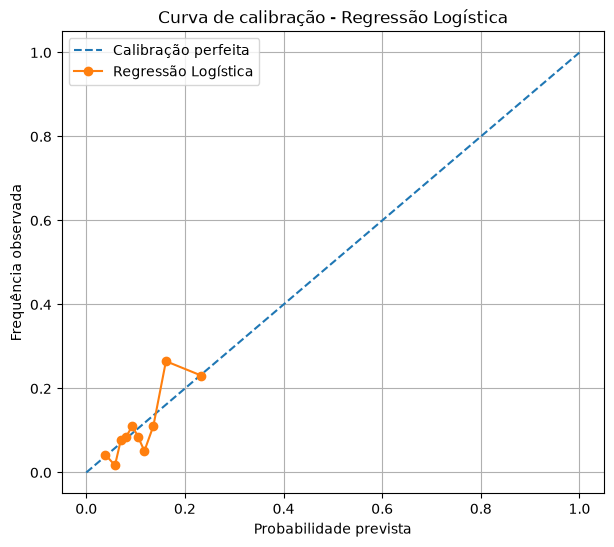

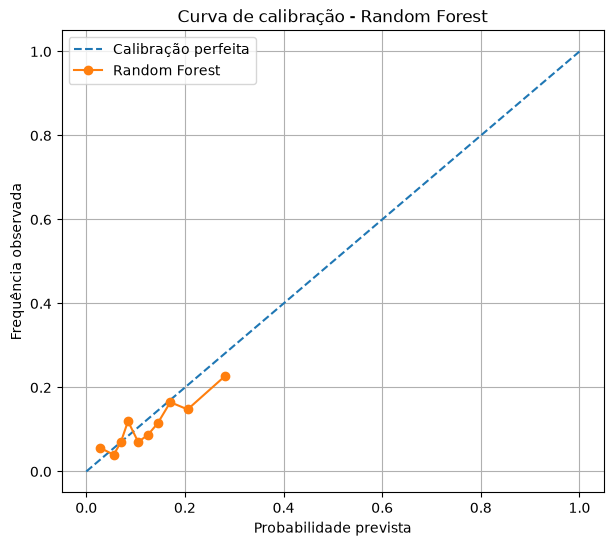

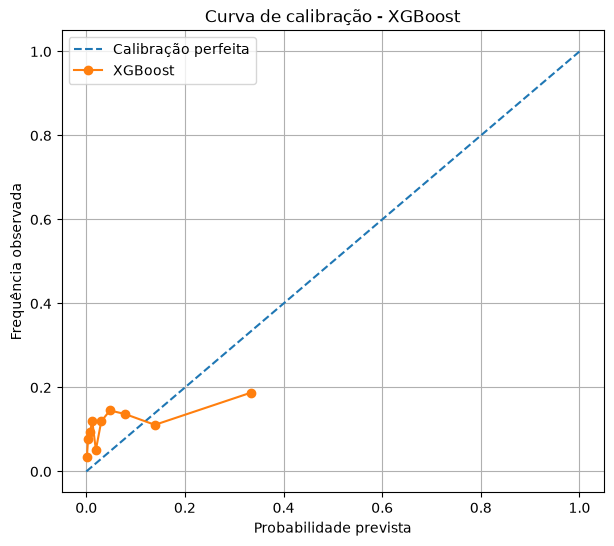

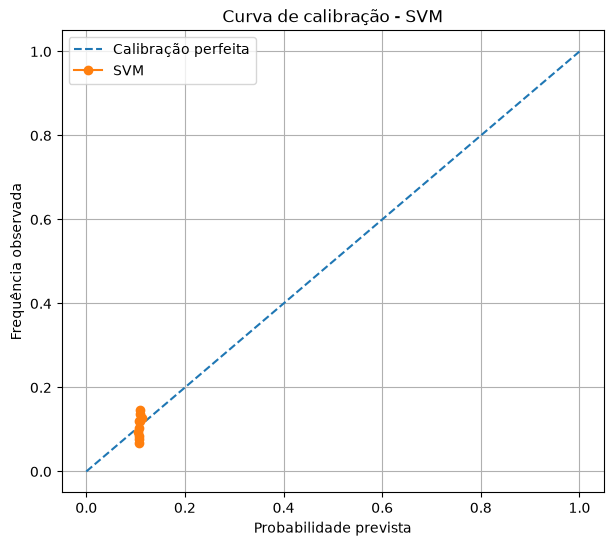

In [14]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

for nome, resultado in resultados_teste.items():

    probabilidades = resultado["probabilidades"]

    prob_real, prob_prevista = calibration_curve(
        y_test,
        probabilidades,
        n_bins=10,
        strategy="quantile"
    )

    plt.figure(figsize=(7, 6))

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Calibração perfeita"
    )

    plt.plot(
        prob_prevista,
        prob_real,
        marker="o",
        label=nome
    )

    plt.xlabel("Probabilidade prevista")
    plt.ylabel("Frequência observada")
    plt.title(f"Curva de calibração - {nome}")
    plt.legend()
    plt.grid()

    plt.show()

In [15]:
from sklearn.metrics import brier_score_loss

print("=== BRIER SCORE ===")

for nome, resultado in resultados_teste.items():

    probabilidades = resultado["probabilidades"]

    brier = brier_score_loss(
        y_test,
        probabilidades
    )

    print(f"{nome}: {brier:.4f}")

=== BRIER SCORE ===
Regressão Logística: 0.0916
Random Forest: 0.0945
XGBoost: 0.1034
SVM: 0.0960


In [16]:
resultados_validacao = validar_modelos(
    modelos,
    X_train,
    y_train
)

In [17]:
for nome, resultado in resultados_validacao.items():

    print("\n==============================")
    print(nome)
    print("==============================")

    print(
        f"ROC-AUC: "
        f"{resultado['media_auc']:.4f} "
        f"+/- "
        f"{resultado['desvio_auc']:.4f}"
    )

    media_brier = resultado.get("media_brier")
    desvio_brier = resultado.get("desvio_brier")

    if media_brier is None or desvio_brier is None:
        print("Brier: não disponível para este modelo.")
        continue

    print(
        f"Brier: "
        f"{media_brier:.4f} "
        f"+/- "
        f"{desvio_brier:.4f}"
    )


Regressão Logística
ROC-AUC: 0.6455 +/- 0.0230
Brier: 0.0940 +/- 0.0014

Random Forest
ROC-AUC: 0.6086 +/- 0.0208
Brier: 0.0970 +/- 0.0012

XGBoost
ROC-AUC: 0.5787 +/- 0.0326
Brier: 0.1070 +/- 0.0029

SVM
ROC-AUC: 0.5096 +/- 0.0306
Brier: 0.0963 +/- 0.0001


In [18]:
import os
import sys
import importlib

cwd = os.getcwd()
project_root = cwd

if os.path.basename(cwd) == "notebooks":
    project_root = os.path.abspath("..")
elif not os.path.exists(os.path.join(cwd, "src")):
    for candidate in [os.path.abspath(".."), os.path.abspath(".")]:
        if os.path.exists(os.path.join(candidate, "src")):
            project_root = candidate
            break

if project_root not in sys.path:
    sys.path.insert(0, project_root)

import src.avaliacao as avaliacao
importlib.reload(avaliacao)

<module 'src.avaliacao' from 'c:\\Users\\Pichau\\Documents\\limezashi\\TCC_SAIS\\src\\avaliacao.py'>

In [19]:
resultados_validacao = avaliacao.validar_modelos(
    modelos,
    X_train,
    y_train
)

In [21]:
import pandas as pd
from sklearn.model_selection import train_test_split

from src.variables import VARIABLES_T0, VARIABLE_TARGET


def carregar_dados(caminho="../data/dataset.csv"):
    df = pd.read_csv(caminho)
    return df


def preparar_dados(caminho="../data/dataset.csv"):
    df = carregar_dados(caminho)

    colunas_esperadas = VARIABLES_T0 + [
        VARIABLE_TARGET,
        "patient_id"
    ]

    colunas_faltantes = [
        coluna
        for coluna in colunas_esperadas
        if coluna not in df.columns
    ]

    if colunas_faltantes:
        raise ValueError(
            f"Colunas ausentes no dataset: {colunas_faltantes}"
        )

    X = df[VARIABLES_T0]
    y = df[VARIABLE_TARGET]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    return X_train, X_test, y_train, y_test

In [22]:
from src.preparacao_dados import preparar_dados
from src.modelos import criar_modelos
from src.avaliacao import (
    treinar_modelos,
    validar_modelos,
    avaliar_modelos
)

X_train, X_test, y_train, y_test = preparar_dados(
    "../data/dataset.csv"
)

modelos = criar_modelos()

modelos_treinados = treinar_modelos(
    modelos,
    X_train,
    y_train
)

resultados_validacao = validar_modelos(
    modelos,
    X_train,
    y_train
)

resultados_teste = avaliar_modelos(
    modelos_treinados,
    X_test,
    y_test
)

c:\Users\Pichau\Documents\limezashi\TCC_SAIS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pichau\Documents\limezashi\TCC_SAIS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pichau\Documents\limezashi\TCC_SAIS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

In [23]:
for nome, resultado in resultados_validacao.items():

    teste = resultados_teste[nome]

    print("=" * 50)
    print(nome)
    print("=" * 50)

    print(
        f"AUC CV:     "
        f"{resultado['media_auc']:.4f} ± "
        f"{resultado['desvio_auc']:.4f}"
    )

    print(
        f"Brier CV:   "
        f"{resultado['media_brier']:.4f} ± "
        f"{resultado['desvio_brier']:.4f}"
    )

    print(
        f"AUC Teste:  "
        f"{teste['auc']:.4f}"
    )

    print(
        f"Brier Teste:"
        f"{teste['brier']:.4f}"
    )

    print()

Regressão Logística
AUC CV:     0.6455 ± 0.0230
Brier CV:   0.0940 ± 0.0014
AUC Teste:  0.6861
Brier Teste:0.0916

Random Forest
AUC CV:     0.6086 ± 0.0208
Brier CV:   0.0970 ± 0.0012
AUC Teste:  0.6401
Brier Teste:0.0945

XGBoost
AUC CV:     0.5787 ± 0.0326
Brier CV:   0.1070 ± 0.0029
AUC Teste:  0.6041
Brier Teste:0.1034

SVM
AUC CV:     0.5096 ± 0.0306
Brier CV:   0.0963 ± 0.0001
AUC Teste:  0.5396
Brier Teste:0.0960



In [24]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, brier_score_loss


def gerar_oof_modelos(modelos, X, y, n_splits=5):

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    probabilidades_oof = {}

    for nome, modelo in modelos.items():

        probabilidades = np.zeros(len(X))

        for indice_treino, indice_validacao in cv.split(X, y):

            modelo_cv = clone(modelo)

            X_fold_treino = X.iloc[indice_treino]
            X_fold_validacao = X.iloc[indice_validacao]

            y_fold_treino = y.iloc[indice_treino]

            modelo_cv.fit(
                X_fold_treino,
                y_fold_treino
            )

            probabilidades[indice_validacao] = (
                modelo_cv
                .predict_proba(X_fold_validacao)[:, 1]
            )

        probabilidades_oof[nome] = probabilidades

    return probabilidades_oof

In [25]:
prob_oof = gerar_oof_modelos(
    modelos,
    X_train,
    y_train
)

In [26]:
for nome, probabilidades in prob_oof.items():

    print(
        f"{nome}: "
        f"mínimo={probabilidades.min():.4f}, "
        f"máximo={probabilidades.max():.4f}, "
        f"média={probabilidades.mean():.4f}"
    )

Regressão Logística: mínimo=0.0125, máximo=0.6373, média=0.1076
Random Forest: mínimo=0.0000, máximo=0.5100, média=0.1211
XGBoost: mínimo=0.0000, máximo=0.8662, média=0.0595
SVM: mínimo=0.0842, máximo=0.2260, média=0.1079


In [27]:
from itertools import combinations

resultados_ensemble = []

nomes_modelos = list(prob_oof.keys())

for nome1, nome2 in combinations(nomes_modelos, 2):

    probabilidade_ensemble = (
        prob_oof[nome1] +
        prob_oof[nome2]
    ) / 2

    auc = roc_auc_score(
        y_train,
        probabilidade_ensemble
    )

    brier = brier_score_loss(
        y_train,
        probabilidade_ensemble
    )

    resultados_ensemble.append({
        "Modelo": f"{nome1} + {nome2}",
        "AUC OOF": auc,
        "Brier OOF": brier
    })

df_ensemble = pd.DataFrame(resultados_ensemble)

df_ensemble = df_ensemble.sort_values(
    by="AUC OOF",
    ascending=False
)

df_ensemble

,Modelo,AUC OOF,Brier OOF
2,Regressão Logística + SVM,0.641968,0.094347
0,Regressão Logística + Random Forest,0.635445,0.094562
1,Regressão Logística + XGBoost,0.626799,0.097593
4,Random Forest + SVM,0.606363,0.095137
3,Random Forest + XGBoost,0.604233,0.098831
5,XGBoost + SVM,0.572486,0.098567


In [28]:
from itertools import combinations

resultados_combinacoes = []

for quantidade in [2, 3, 4]:

    for combinacao in combinations(nomes_modelos, quantidade):

        probabilidades = np.column_stack([
            prob_oof[nome]
            for nome in combinacao
        ])

        probabilidade_media = probabilidades.mean(axis=1)

        auc = roc_auc_score(
            y_train,
            probabilidade_media
        )

        brier = brier_score_loss(
            y_train,
            probabilidade_media
        )

        resultados_combinacoes.append({
            "Modelos": " + ".join(combinacao),
            "Quantidade": quantidade,
            "AUC OOF": auc,
            "Brier OOF": brier
        })

df_combinacoes = pd.DataFrame(
    resultados_combinacoes
)

df_combinacoes = df_combinacoes.sort_values(
    by="AUC OOF",
    ascending=False
)

df_combinacoes


,Modelos,Quantidade,AUC OOF,Brier OOF
2,Regressão Logística + SVM,2,0.641968,0.094347
0,Regressão Logística + Random Forest,2,0.635445,0.094562
7,Regressão Logística + Random Forest + SVM,3,0.634108,0.094329
1,Regressão Logística + XGBoost,2,0.626799,0.097593
6,Regressão Logística + Random Forest + XGBoost,3,0.626638,0.096225
10,Regressão Logística + Random Forest + XGBoost ...,4,0.625601,0.095486
8,Regressão Logística + XGBoost + SVM,3,0.625252,0.096090
4,Random Forest + SVM,2,0.606363,0.095137
3,Random Forest + XGBoost,2,0.604233,0.098831
9,Random Forest + XGBoost + SVM,3,0.602739,0.096659


In [29]:
resultados_pesos = []

pares = [
    ("Regressão Logística", "Random Forest"),
    ("Regressão Logística", "XGBoost"),
    ("Regressão Logística", "SVM")
]

pesos = np.arange(0.0, 1.01, 0.05)

for modelo1, modelo2 in pares:

    p1 = prob_oof[modelo1]
    p2 = prob_oof[modelo2]

    for peso1 in pesos:

        peso2 = 1 - peso1

        probabilidade = (
            peso1 * p1 +
            peso2 * p2
        )

        auc = roc_auc_score(
            y_train,
            probabilidade
        )

        brier = brier_score_loss(
            y_train,
            probabilidade
        )

        resultados_pesos.append({
            "Modelo 1": modelo1,
            "Modelo 2": modelo2,
            "Peso Modelo 1": peso1,
            "Peso Modelo 2": peso2,
            "AUC OOF": auc,
            "Brier OOF": brier
        })

df_pesos = pd.DataFrame(resultados_pesos)

df_pesos = df_pesos.sort_values(
    by="AUC OOF",
    ascending=False
)

df_pesos.head(15)

,Modelo 1,Modelo 2,Peso Modelo 1,Peso Modelo 2,AUC OOF,Brier OOF
18,Regressão Logística,Random Forest,0.90,0.10,0.646407,0.093952
17,Regressão Logística,Random Forest,0.85,0.15,0.646335,0.093964
16,Regressão Logística,Random Forest,0.80,0.20,0.645895,0.093995
19,Regressão Logística,Random Forest,0.95,0.05,0.645852,0.093958
15,Regressão Logística,Random Forest,0.75,0.25,0.645146,0.094043
20,Regressão Logística,Random Forest,1.00,0.00,0.644576,0.093983
41,Regressão Logística,XGBoost,1.00,0.00,0.644576,0.093983
62,Regressão Logística,SVM,1.00,0.00,0.644576,0.093983
61,Regressão Logística,SVM,0.95,0.05,0.644461,0.093949
60,Regressão Logística,SVM,0.90,0.10,0.644294,0.093931


In [30]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, brier_score_loss

modelo_rl = clone(
    modelos["Regressão Logística"]
)

modelo_rf = clone(
    modelos["Random Forest"]
)

modelo_rl.fit(
    X_train,
    y_train
)

modelo_rf.fit(
    X_train,
    y_train
)

prob_rl = modelo_rl.predict_proba(
    X_test
)[:, 1]

prob_rf = modelo_rf.predict_proba(
    X_test
)[:, 1]

# Ensemble ponderado: 90% RL + 10% RF
prob_ensemble = (
    0.90 * prob_rl +
    0.10 * prob_rf
)

auc_ensemble = roc_auc_score(
    y_test,
    prob_ensemble
)

brier_ensemble = brier_score_loss(
    y_test,
    prob_ensemble
)

print("RL + RF (90% / 10%)")
print(f"AUC Teste:   {auc_ensemble:.4f}")
print(f"Brier Teste: {brier_ensemble:.4f}")

RL + RF (90% / 10%)
AUC Teste:   0.6867
Brier Teste: 0.0915


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve


# Probabilidades da Regressão Logística
prob_rl = modelo_rl.predict_proba(X_test)[:, 1]

# Probabilidades do ensemble 90% RL + 10% RF
prob_ensemble = (
    0.90 * prob_rl +
    0.10 * prob_rf
)


# Curva de calibração
fracao_rl, media_prob_rl = calibration_curve(
    y_test,
    prob_rl,
    n_bins=10,
    strategy="quantile"
)

fracao_ensemble, media_prob_ensemble = calibration_curve(
    y_test,
    prob_ensemble,
    n_bins=10,
    strategy="quantile"
)


print("Calibração calculada.")
print(f"RL: {len(media_prob_rl)} pontos")
print(f"Ensemble: {len(media_prob_ensemble)} pontos")

Calibração calculada.
RL: 10 pontos
Ensemble: 10 pontos


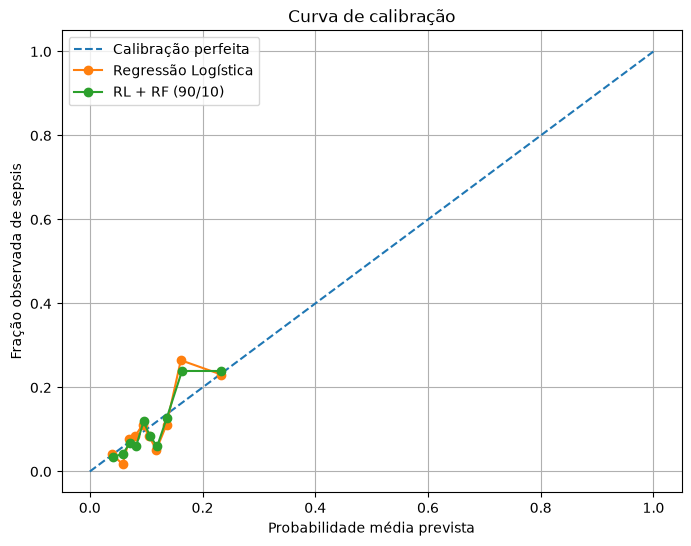

In [32]:
plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Calibração perfeita"
)

plt.plot(
    media_prob_rl,
    fracao_rl,
    marker="o",
    label="Regressão Logística"
)

plt.plot(
    media_prob_ensemble,
    fracao_ensemble,
    marker="o",
    label="RL + RF (90/10)"
)

plt.xlabel("Probabilidade média prevista")
plt.ylabel("Fração observada de sepsis")

plt.title("Curva de calibração")

plt.legend()
plt.grid(True)

plt.show()

In [33]:
from sklearn.metrics import brier_score_loss

brier_rl = brier_score_loss(
    y_test,
    prob_rl
)

brier_ensemble = brier_score_loss(
    y_test,
    prob_ensemble
)

print("Brier Score")
print("-" * 30)
print(f"Regressão Logística: {brier_rl:.4f}")
print(f"RL + RF (90/10):     {brier_ensemble:.4f}")

Brier Score
------------------------------
Regressão Logística: 0.0916
RL + RF (90/10):     0.0915


In [34]:
print("Regressão Logística")
print(f"Mínimo:  {prob_rl.min():.4f}")
print(f"Máximo:  {prob_rl.max():.4f}")
print(f"Média:   {prob_rl.mean():.4f}")
print(f"Mediana: {np.median(prob_rl):.4f}")

print()

print("RL + RF (90/10)")
print(f"Mínimo:  {prob_ensemble.min():.4f}")
print(f"Máximo:  {prob_ensemble.max():.4f}")
print(f"Média:   {prob_ensemble.mean():.4f}")
print(f"Mediana: {np.median(prob_ensemble):.4f}")

Regressão Logística
Mínimo:  0.0177
Máximo:  0.5332
Média:   0.1094
Mediana: 0.0992

RL + RF (90/10)
Mínimo:  0.0195
Máximo:  0.5169
Média:   0.1107
Mediana: 0.1009


In [35]:
print(f"Prevalência observada: {y_test.mean():.4f}")
print(f"Média das probabilidades RL: {prob_rl.mean():.4f}")
print(f"Média das probabilidades Ensemble: {prob_ensemble.mean():.4f}")

Prevalência observada: 0.1076
Média das probabilidades RL: 0.1094
Média das probabilidades Ensemble: 0.1107


In [36]:
import numpy as np
import pandas as pd

from itertools import combinations
from sklearn.metrics import roc_auc_score, brier_score_loss


resultados_pesos_2 = []

nomes_modelos = list(prob_oof.keys())

# Todas as combinações de 2 modelos
for modelo1, modelo2 in combinations(nomes_modelos, 2):

    p1 = prob_oof[modelo1]
    p2 = prob_oof[modelo2]

    # Pesos de 0% a 100%, em intervalos de 5%
    for peso1 in np.arange(0.0, 1.01, 0.05):

        peso2 = 1.0 - peso1

        probabilidade = (
            peso1 * p1 +
            peso2 * p2
        )

        auc = roc_auc_score(
            y_train,
            probabilidade
        )

        brier = brier_score_loss(
            y_train,
            probabilidade
        )

        resultados_pesos_2.append({
            "Modelo 1": modelo1,
            "Modelo 2": modelo2,
            "Peso Modelo 1": round(peso1, 2),
            "Peso Modelo 2": round(peso2, 2),
            "AUC OOF": auc,
            "Brier OOF": brier
        })


df_pesos_2 = pd.DataFrame(resultados_pesos_2)

df_pesos_2 = df_pesos_2.sort_values(
    by="AUC OOF",
    ascending=False
).reset_index(drop=True)

df_pesos_2

,Modelo 1,Modelo 2,Peso Modelo 1,Peso Modelo 2,AUC OOF,Brier OOF
0,Regressão Logística,Random Forest,0.90,0.10,0.646407,0.093952
1,Regressão Logística,Random Forest,0.85,0.15,0.646335,0.093964
2,Regressão Logística,Random Forest,0.80,0.20,0.645895,0.093995
3,Regressão Logística,Random Forest,0.95,0.05,0.645852,0.093958
4,Regressão Logística,Random Forest,0.75,0.25,0.645146,0.094043
...,...,...,...,...,...,...
121,XGBoost,SVM,0.10,0.90,0.549949,0.096242
122,XGBoost,SVM,0.05,0.95,0.536285,0.096226
123,Regressão Logística,SVM,0.00,1.00,0.502814,0.096270
124,Random Forest,SVM,0.00,1.00,0.502814,0.096270


In [37]:
from itertools import combinations

resultados_pesos_3 = []

for modelo1, modelo2, modelo3 in combinations(nomes_modelos, 3):

    p1 = prob_oof[modelo1]
    p2 = prob_oof[modelo2]
    p3 = prob_oof[modelo3]

    pesos = np.arange(0.0, 1.01, 0.05)

    for peso1 in pesos:

        for peso2 in pesos:

            peso3 = 1.0 - peso1 - peso2

            # Ignora combinações com peso negativo
            if peso3 < 0:
                continue

            probabilidade = (
                peso1 * p1 +
                peso2 * p2 +
                peso3 * p3
            )

            auc = roc_auc_score(
                y_train,
                probabilidade
            )

            brier = brier_score_loss(
                y_train,
                probabilidade
            )

            resultados_pesos_3.append({
                "Modelo 1": modelo1,
                "Modelo 2": modelo2,
                "Modelo 3": modelo3,
                "Peso Modelo 1": round(peso1, 2),
                "Peso Modelo 2": round(peso2, 2),
                "Peso Modelo 3": round(peso3, 2),
                "AUC OOF": auc,
                "Brier OOF": brier
            })


df_pesos_3 = pd.DataFrame(
    resultados_pesos_3
)

df_pesos_3 = df_pesos_3.sort_values(
    by="AUC OOF",
    ascending=False
).reset_index(drop=True)

df_pesos_3

,Modelo 1,Modelo 2,Modelo 3,Peso Modelo 1,Peso Modelo 2,Peso Modelo 3,AUC OOF,Brier OOF
0,Regressão Logística,Random Forest,SVM,0.85,0.10,0.05,0.646267,0.093923
1,Regressão Logística,Random Forest,SVM,0.80,0.10,0.10,0.646151,0.093909
2,Regressão Logística,Random Forest,SVM,0.80,0.15,0.05,0.646129,0.093937
3,Regressão Logística,Random Forest,SVM,0.75,0.10,0.15,0.645935,0.093910
4,Regressão Logística,Random Forest,SVM,0.75,0.15,0.10,0.645931,0.093925
...,...,...,...,...,...,...,...,...
867,Random Forest,XGBoost,SVM,0.00,0.05,0.95,0.536285,0.096226
868,Regressão Logística,XGBoost,SVM,0.00,0.05,0.95,0.536285,0.096226
869,Random Forest,XGBoost,SVM,0.00,0.00,1.00,0.502814,0.096270
870,Regressão Logística,Random Forest,SVM,0.00,0.00,1.00,0.502814,0.096270


In [38]:
df_pesos_3.head(20)

,Modelo 1,Modelo 2,Modelo 3,Peso Modelo 1,Peso Modelo 2,Peso Modelo 3,AUC OOF,Brier OOF
0,Regressão Logística,Random Forest,SVM,0.85,0.10,0.05,0.646267,0.093923
1,Regressão Logística,Random Forest,SVM,0.80,0.10,0.10,0.646151,0.093909
2,Regressão Logística,Random Forest,SVM,0.80,0.15,0.05,0.646129,0.093937
3,Regressão Logística,Random Forest,SVM,0.75,0.10,0.15,0.645935,0.093910
4,Regressão Logística,Random Forest,SVM,0.75,0.15,0.10,0.645931,0.093925
5,Regressão Logística,Random Forest,SVM,0.70,0.10,0.20,0.645769,0.093928
6,Regressão Logística,Random Forest,SVM,0.90,0.05,0.05,0.645767,0.093927
7,Regressão Logística,Random Forest,SVM,0.70,0.15,0.15,0.645735,0.093929
8,Regressão Logística,Random Forest,SVM,0.75,0.20,0.05,0.645651,0.093969
9,Regressão Logística,Random Forest,SVM,0.85,0.05,0.10,0.645646,0.093911


In [39]:
melhores_por_combinacao_3 = (
    df_pesos_3
    .groupby(
        ["Modelo 1", "Modelo 2", "Modelo 3"],
        as_index=False
    )
    .apply(
        lambda grupo: grupo.loc[
            grupo["AUC OOF"].idxmax()
        ]
    )
    .reset_index(drop=True)
)

melhores_por_combinacao_3

,Modelo 1,Modelo 2,Modelo 3,Peso Modelo 1,Peso Modelo 2,Peso Modelo 3,AUC OOF,Brier OOF
0,Random Forest,XGBoost,SVM,0.90,0.05,0.05,0.608985,0.096577
1,Regressão Logística,Random Forest,SVM,0.85,0.10,0.05,0.646267,0.093923
2,Regressão Logística,Random Forest,XGBoost,0.85,0.10,0.05,0.645225,0.094067
3,Regressão Logística,XGBoost,SVM,1.00,0.00,0.00,0.644576,0.093983


In [40]:
from itertools import combinations

resultados_pesos_4 = []

p = np.arange(0.0, 1.01, 0.05)

p1 = prob_oof["Regressão Logística"]
p2 = prob_oof["Random Forest"]
p3 = prob_oof["XGBoost"]
p4 = prob_oof["SVM"]

for peso1 in p:
    for peso2 in p:
        for peso3 in p:

            peso4 = 1.0 - peso1 - peso2 - peso3

            if peso4 < 0:
                continue

            probabilidade = (
                peso1 * p1 +
                peso2 * p2 +
                peso3 * p3 +
                peso4 * p4
            )

            auc = roc_auc_score(
                y_train,
                probabilidade
            )

            brier = brier_score_loss(
                y_train,
                probabilidade
            )

            resultados_pesos_4.append({
                "Peso RL": round(peso1, 2),
                "Peso RF": round(peso2, 2),
                "Peso XGB": round(peso3, 2),
                "Peso SVM": round(peso4, 2),
                "AUC OOF": auc,
                "Brier OOF": brier
            })


df_pesos_4 = pd.DataFrame(
    resultados_pesos_4
)

df_pesos_4 = df_pesos_4.sort_values(
    by="AUC OOF",
    ascending=False
).reset_index(drop=True)

In [41]:
df_pesos_4.head(20)

,Peso RL,Peso RF,Peso XGB,Peso SVM,AUC OOF,Brier OOF
0,0.85,0.10,0.00,0.05,0.646267,0.093923
1,0.80,0.10,0.00,0.10,0.646151,0.093909
2,0.80,0.15,0.00,0.05,0.646129,0.093937
3,0.75,0.10,0.00,0.15,0.645935,0.093910
4,0.75,0.15,0.00,0.10,0.645931,0.093925
5,0.70,0.10,0.00,0.20,0.645769,0.093928
6,0.90,0.05,0.00,0.05,0.645767,0.093927
7,0.70,0.15,0.00,0.15,0.645735,0.093929
8,0.75,0.20,0.00,0.05,0.645651,0.093969
9,0.85,0.05,0.00,0.10,0.645646,0.093911


In [42]:
df_pesos_4_brier = (
    df_pesos_4
    .sort_values(
        by="Brier OOF",
        ascending=True
    )
    .reset_index(drop=True)
)

df_pesos_4_brier.head(20)

,Peso RL,Peso RF,Peso XGB,Peso SVM,AUC OOF,Brier OOF
0,0.80,0.10,0.0,0.10,0.646151,0.093909
1,0.80,0.05,0.0,0.15,0.645494,0.093910
2,0.75,0.10,0.0,0.15,0.645935,0.093910
3,0.85,0.05,0.0,0.10,0.645646,0.093911
4,0.85,0.10,0.0,0.05,0.646267,0.093923
5,0.75,0.15,0.0,0.10,0.645931,0.093925
6,0.75,0.05,0.0,0.20,0.645380,0.093926
7,0.90,0.05,0.0,0.05,0.645767,0.093927
8,0.70,0.10,0.0,0.20,0.645769,0.093928
9,0.85,0.00,0.0,0.15,0.644146,0.093929


In [43]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, brier_score_loss

# =========================
# Treinamento dos modelos
# =========================

modelo_rl = clone(modelos["Regressão Logística"])
modelo_rf = clone(modelos["Random Forest"])
modelo_svm = clone(modelos["SVM"])

modelo_rl.fit(X_train, y_train)
modelo_rf.fit(X_train, y_train)
modelo_svm.fit(X_train, y_train)


# =========================
# Probabilidades no X_test
# =========================

prob_rl = modelo_rl.predict_proba(X_test)[:, 1]
prob_rf = modelo_rf.predict_proba(X_test)[:, 1]
prob_svm = modelo_svm.predict_proba(X_test)[:, 1]


# =========================
# Candidato A - RL
# =========================

prob_candidato_a = prob_rl


# =========================
# Candidato B - RL + RF
# =========================

prob_candidato_b = (
    0.90 * prob_rl +
    0.10 * prob_rf
)


# =========================
# Candidato C - RL + RF + SVM
# =========================

prob_candidato_c = (
    0.80 * prob_rl +
    0.10 * prob_rf +
    0.10 * prob_svm
)


# =========================
# Avaliação
# =========================

resultados_finais = []

candidatos = {
    "Regressão Logística": prob_candidato_a,
    "RL + RF (90/10)": prob_candidato_b,
    "RL + RF + SVM (80/10/10)": prob_candidato_c
}


for nome, probabilidades in candidatos.items():

    auc = roc_auc_score(
        y_test,
        probabilidades
    )

    brier = brier_score_loss(
        y_test,
        probabilidades
    )

    resultados_finais.append({
        "Modelo": nome,
        "AUC Teste": auc,
        "Brier Teste": brier
    })


df_resultados_finais = pd.DataFrame(
    resultados_finais
)

df_resultados_finais

,Modelo,AUC Teste,Brier Teste
0,Regressão Logística,0.686071,0.091550
1,RL + RF (90/10),0.686732,0.091511
2,RL + RF + SVM (80/10/10),0.686679,0.091681


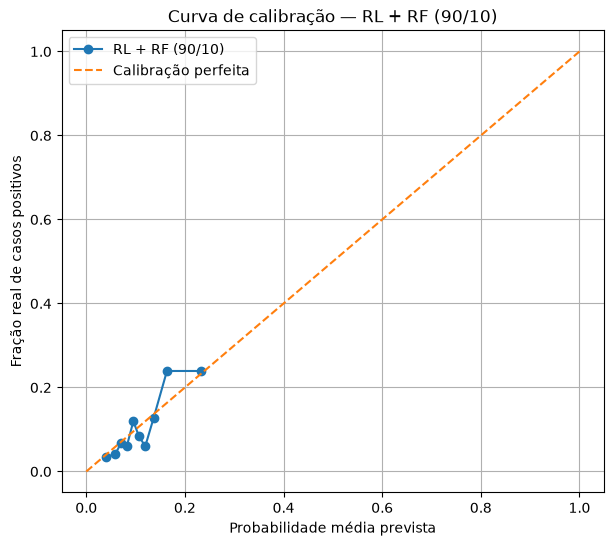

In [44]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

prob_ensemble = prob_candidato_b

fracao_positivos, media_predita = calibration_curve(
    y_test,
    prob_ensemble,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    media_predita,
    fracao_positivos,
    marker="o",
    label="RL + RF (90/10)"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Calibração perfeita"
)

plt.xlabel("Probabilidade média prevista")
plt.ylabel("Fração real de casos positivos")
plt.title("Curva de calibração — RL + RF (90/10)")
plt.legend()
plt.grid(True)

plt.show()

In [45]:
import numpy as np

print("Distribuição das probabilidades — RL + RF (90/10)")
print(f"Mínimo:   {prob_ensemble.min():.4f}")
print(f"Máximo:   {prob_ensemble.max():.4f}")
print(f"Média:    {prob_ensemble.mean():.4f}")
print(f"Mediana:  {np.median(prob_ensemble):.4f}")

print("\nPercentis:")
print(f"P25:      {np.percentile(prob_ensemble, 25):.4f}")
print(f"P75:      {np.percentile(prob_ensemble, 75):.4f}")
print(f"P90:      {np.percentile(prob_ensemble, 90):.4f}")
print(f"P95:      {np.percentile(prob_ensemble, 95):.4f}")

Distribuição das probabilidades — RL + RF (90/10)
Mínimo:   0.0195
Máximo:   0.5169
Média:    0.1107
Mediana:  0.1009

Percentis:
P25:      0.0709
P75:      0.1362
P90:      0.1841
P95:      0.2194


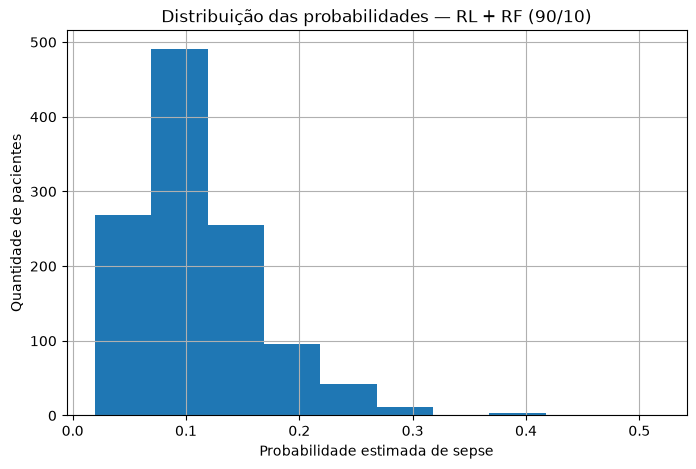

In [46]:
plt.figure(figsize=(8, 5))

plt.hist(
    prob_ensemble,
    bins=10
)

plt.xlabel("Probabilidade estimada de sepse")
plt.ylabel("Quantidade de pacientes")
plt.title("Distribuição das probabilidades — RL + RF (90/10)")
plt.grid(True)

plt.show()

In [47]:
prevalencia_teste = y_test.mean()

print(f"Prevalência real no X_test: {prevalencia_teste:.4f}")
print(f"Média das probabilidades:    {prob_ensemble.mean():.4f}")

Prevalência real no X_test: 0.1076
Média das probabilidades:    0.1107


---- TESTE DE MODELO FINAL----

In [49]:
from src.predicao import treinar, prever

In [50]:
modelo_final = treinar(
    X_train,
    y_train
)

In [51]:
paciente = {
    "leucocitos": 12.5,
    "neutrofilos": 9.8,
    "plaquetas": 180,
    "temperatura": 38.2,
    "fc": 105,
    "pas": 105,
    "lactato": 2.1,
    "creatinina": 1.3,
    "pao2_fio2": 180,
    "rnl": 8.5,
    "bastonetes": 8.0
}

In [52]:
probabilidade = prever(
    modelo_final,
    paciente
)

print(
    f"Probabilidade estimada: "
    f"{probabilidade:.2%}"
)

Probabilidade estimada: 18.35%


In [53]:
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss
)

auc = roc_auc_score(
    y_test,
    prob_final
)

brier = brier_score_loss(
    y_test,
    prob_final
)

print(f"AUC: {auc:.6f}")
print(f"Brier: {brier:.6f}")

NameError: name 'prob_final' is not defined